# 02 : Baseline (M0: TF-IDF + Logistic Regression)

Purpose: train the M0 baseline on the training split, evaluate it on the
validation split, and report the full metric set with ROC, precision-recall
and confusion-matrix figures. This is the reference point M1 has to beat.
Author: Colile Sibanda.

**Test-set invariant:** this notebook touches `train.csv` and
`validation.csv` only. `test.csv` is loaded in `04_evaluate.ipynb`, once.

In [1]:
import json
import os
import subprocess
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

# Notebooks run with the kernel's cwd set to notebooks/; load_config() reads
# a path relative to the repo root, so move up to it first.
_repo_root = Path.cwd()
while not (_repo_root / "pyproject.toml").exists():
    _repo_root = _repo_root.parent
os.chdir(_repo_root)

from phishlens.config.loader import load_config
from phishlens.config.seeding import set_global_seed
from phishlens.models.baseline import build_baseline

config = load_config()
set_global_seed(config.seed)
commit_hash = subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip()

print(f"Config seed: {config.seed}")
print(f"Commit hash: {commit_hash}")
print(f"Run date: {datetime.now().isoformat(timespec='seconds')}")

Config seed: 42
Commit hash: 0e9063658de8fc78dcfb774bc202901b2487d116
Run date: 2026-09-26T10:37:22


## Load the training and validation splits

`test.csv` is never read here : see the invariant above.

In [2]:
processed_dir = Path(config.paths.processed)
train_df = pd.read_csv(processed_dir / "train.csv")
validation_df = pd.read_csv(processed_dir / "validation.csv")

label_column = config.data.label_column
positive_label = config.data.positive_label

print(f"Train rows: {len(train_df)}")
print(f"Validation rows: {len(validation_df)}")
print(f"Train positive rate: {train_df[label_column].mean():.4f}")
print(f"Validation positive rate: {validation_df[label_column].mean():.4f}")

Train rows: 57736
Validation rows: 12372
Train positive rate: 0.5200
Validation positive rate: 0.5200


## Train M0

TF-IDF fit on the training split only, into a class-weighted Logistic
Regression. `build_baseline` is a factory : see `src/phishlens/models/baseline.py`.

In [3]:
pipeline = build_baseline(config)
pipeline.fit(train_df["text"].tolist(), train_df[label_column].to_numpy())

vocab_size = len(pipeline.named_steps["tfidf"].vocabulary_)
print(f"TF-IDF vocabulary size: {vocab_size}")

TF-IDF vocabulary size: 50000


## Predict on validation

In [4]:
threshold = config.evaluation.decision_threshold

y_true = validation_df[label_column].to_numpy()
y_prob = pipeline.predict_proba(validation_df["text"].tolist())[:, 1]
y_pred = (y_prob >= threshold).astype(int)

assert positive_label == 1, "Positive class must be label 1"

## Metric table

Accuracy, precision, recall, F1, macro-F1, AUC-ROC and average precision at
the configured decision threshold.

In [5]:
metrics = {
    "accuracy": accuracy_score(y_true, y_pred),
    "precision": precision_score(y_true, y_pred, pos_label=positive_label),
    "recall": recall_score(y_true, y_pred, pos_label=positive_label),
    "f1": f1_score(y_true, y_pred, pos_label=positive_label),
    "macro_f1": f1_score(y_true, y_pred, average="macro"),
    "auc_roc": roc_auc_score(y_true, y_prob),
    "average_precision": average_precision_score(y_true, y_prob),
}

metrics_table = pd.DataFrame([metrics]).T.rename(columns={0: "value"})
metrics_table["value"] = metrics_table["value"].round(4)
metrics_table

,value
accuracy,0.9838
precision,0.9834
recall,0.9855
f1,0.9845
macro_f1,0.9838
auc_roc,0.9985
average_precision,0.9986


## Figures: ROC, precision-recall, confusion matrix

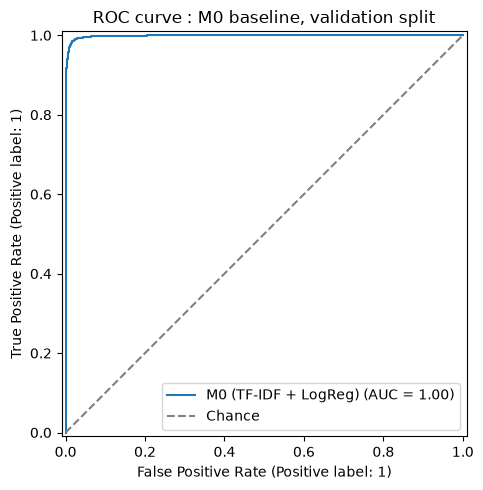

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_true, y_prob, ax=ax, name="M0 (TF-IDF + LogReg)")
ax.set_title("ROC curve : M0 baseline, validation split")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Chance")
ax.legend()
fig.tight_layout()
roc_path = Path(config.paths.figures) / "m0_roc_curve.png"
roc_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(roc_path, dpi=config.evaluation.figure_dpi)
plt.show()

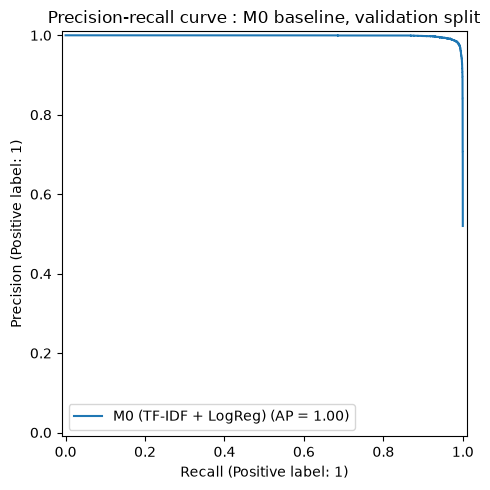

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(
    y_true, y_prob, ax=ax, name="M0 (TF-IDF + LogReg)"
)
ax.set_title("Precision-recall curve : M0 baseline, validation split")
fig.tight_layout()
pr_path = Path(config.paths.figures) / "m0_precision_recall_curve.png"
fig.savefig(pr_path, dpi=config.evaluation.figure_dpi)
plt.show()

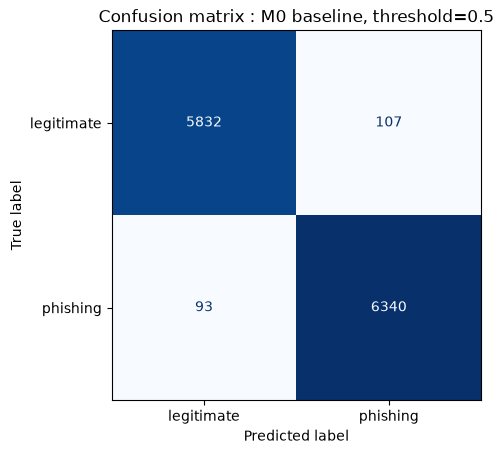

Confusion matrix [[TN, FP], [FN, TP]]:
[[5832  107]
 [  93 6340]]


In [8]:
fig, ax = plt.subplots(figsize=(5, 5))
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["legitimate", "phishing"]).plot(
    ax=ax, cmap="Blues", colorbar=False
)
ax.set_title(f"Confusion matrix : M0 baseline, threshold={threshold}")
fig.tight_layout()
cm_path = Path(config.paths.figures) / "m0_confusion_matrix.png"
fig.savefig(cm_path, dpi=config.evaluation.figure_dpi)
plt.show()

print(f"Confusion matrix [[TN, FP], [FN, TP]]:\n{cm}")

## Save results

Results plus enough context (commit, seed, config hash, threshold, split
sizes) that a number in the report traces back to the run that produced it.

In [9]:
from phishlens.data.splitter import config_hash

results = {
    "model": "m0_tfidf_logreg",
    "split_evaluated": "validation",
    "threshold": threshold,
    "seed": config.seed,
    "commit_hash": commit_hash,
    "config_hash": config_hash(config),
    "vocabulary_size": vocab_size,
    "train_rows": len(train_df),
    "validation_rows": len(validation_df),
    "metrics": {key: round(float(value), 4) for key, value in metrics.items()},
}

metrics_path = Path(config.paths.metrics) / "m0_baseline.json"
metrics_path.parent.mkdir(parents=True, exist_ok=True)
metrics_path.write_text(json.dumps(results, indent=2, sort_keys=True) + "\n", encoding="utf-8")

print(f"Metrics written to: {metrics_path}")
results

Metrics written to: artifacts\metrics\m0_baseline.json


{'model': 'm0_tfidf_logreg',
 'split_evaluated': 'validation',
 'threshold': 0.5,
 'seed': 42,
 'commit_hash': '0e9063658de8fc78dcfb774bc202901b2487d116',
 'config_hash': '3f78ae66c380fce1',
 'vocabulary_size': 50000,
 'train_rows': 57736,
 'validation_rows': 12372,
 'metrics': {'accuracy': 0.9838,
  'precision': 0.9834,
  'recall': 0.9855,
  'f1': 0.9845,
  'macro_f1': 0.9838,
  'auc_roc': 0.9985,
  'average_precision': 0.9986}}